# CSCI E-89 Deep Learning — Assignment 8, Problem 1
### Predicting the opening stock price of **Microsoft (MSFT)** with an RNN and an LSTM
**Student:** Hussein Jawad &nbsp;&nbsp;|&nbsp;&nbsp; **Framework:** PyTorch (same code style as the class notebooks `1_RNN_apple_stock_prediction` and `2_LSTM_apple_stock_prediction`)

**Contents**
1. Approach
2. Problem 1 solution (Steps 1–10)
3. Results and discussion
4. Appendix — *What is an RNN and how does it work?* A visual, step-by-step guide for beginners

> **How to run:** open this notebook in Google Colab, choose **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**.
> Training two models for 100 epochs takes a few minutes on a GPU and much longer on a CPU.

# 1. Approach

**Goal.** Use the code from class to train a recurrent neural network on historical daily
**opening prices** of a company other than Apple, then use it to "predict" the opening price
for each trading day of a later, unseen test period.

**Company.** I chose **Microsoft (ticker `MSFT`)**. It has traded publicly since 1986, so a full
history from January 2016 is available and no shortening of the period is needed.

**Data (downloaded with the `yfinance` library from Yahoo Finance).**

| Set | Requested period | What it is used for |
|---|---|---|
| Training | Jan 1, 2016 → Sep 6, 2026 | Fit the scaler and train the networks |
| Test | Sep 9, 2026 → Oct 10, 2026 | Never seen in training; used only to measure predictions |

Note: September 6, 2026 is a Sunday and October 10, 2026 is a Saturday, so the last trading days actually
present are Friday Sep 4 and Friday Oct 9. Monday Sep 7 is Labor Day (market closed) and Sep 8 is
deliberately left out, exactly as the assignment specifies.

**Method (same pipeline as the class notebooks).**
1. **Download and clean** the `Date` and `Open` columns, sorted from oldest to newest.
2. **Scale** prices to the range [0, 1] with `MinMaxScaler`, fitted **only on training data** (so no information from the test period leaks into training).
3. **Create sliding windows:** each training example is the previous **60 trading days** (input `X`) and the **next day's** opening price (target `y`).
4. **Build the model** from class: 4 stacked recurrent layers with 50 hidden units each, Dropout 0.2 after every layer, and a Linear layer that outputs one number. One small class builds **both** the vanilla **RNN** (notebook 1) and the **LSTM** (notebook 2), because the only difference is the type of recurrent layer.
5. **Train** each model for 100 epochs with the Adam optimizer, mean-squared-error loss and batch size 32. Gradient clipping is kept from the RNN notebook.
6. **Predict the test period** with *rolling one-step-ahead* prediction: to predict day *t*, the model sees the 60 actual opening prices before day *t*.
7. **Convert back to dollars**, report MAE/RMSE and compare against a simple **baseline** that says "tomorrow's open = today's open". A model is only useful if it beats this baseline.
8. **Plot** actual and predicted prices, and **save** the trained models (`torch.save`, the PyTorch counterpart of Keras' `model.save('...')`).
9. As an extra, forecast the opening price for the **next trading day after the test period**.

**Keeping it simple.** Only the opening price is used as a feature, and the hyperparameters are the ones from class.
One model class, one training function and one prediction function are reused for both the RNN and the LSTM.

# 2. Problem 1 solution

## Step 0 — Install the data-download library
Google Colab already includes PyTorch, NumPy, pandas, matplotlib and scikit-learn. `yfinance` downloads prices from Yahoo Finance.
It is usually pre-installed as well, and the command below makes sure it is present and up to date.

In [ ]:
# "%pip" runs pip inside the current notebook kernel, so the package is installed for this notebook.
# "-q" (quiet) hides the long installation log; "-U" upgrades yfinance if an older version is present,
# because Yahoo Finance changes its website often and older yfinance versions can stop working.
%pip install -q -U yfinance

## Step 1 — Import libraries, choose settings (hyperparameters), and pick a device
The settings below are the same as in the class notebooks. `TICKER` and the four dates define the data.

In [ ]:
from pathlib import Path          # Path builds file/folder paths that work on any operating system.
import random                     # Python's built-in random-number generator (we seed it for repeatability).
import numpy as np                # NumPy: fast arrays and math; used to build the sliding windows.
import pandas as pd               # pandas: tables (DataFrames) for reading, cleaning and saving the price data.
import matplotlib.pyplot as plt   # matplotlib: draws all charts in this notebook.
import yfinance as yf             # yfinance: downloads historical stock prices from Yahoo Finance.
from sklearn.preprocessing import MinMaxScaler  # Rescales prices into the range [0, 1].
import torch                      # PyTorch: the deep-learning library used to build and train the networks.
from torch import nn              # nn holds the neural-network building blocks (RNN, LSTM, Linear, Dropout, losses).
from torch.utils.data import TensorDataset, DataLoader  # Pair inputs with targets and serve them in mini-batches.

TICKER = "MSFT"                   # The company we model: Microsoft (any ticker except Apple's would work).
TRAIN_START = "2016-01-01"        # First day of the training period (from the assignment).
TRAIN_END = "2026-09-06"          # Last day of the training period (from the assignment, inclusive).
TEST_START = "2026-09-09"         # First day of the test period (from the assignment).
TEST_END = "2026-10-10"           # Last day of the test period (from the assignment, inclusive).

DATA_DIR = Path.cwd() / "data"      # Folder where the downloaded CSV files are saved.
OUTPUT_DIR = Path.cwd() / "output"  # Folder where the trained models are saved.
LOOKBACK = 60                     # Each prediction uses the previous 60 trading days (about 3 months).
HIDDEN_SIZE = 50                  # Number of hidden units (the size of the "memory" vector) in every recurrent layer.
DROPOUT = 0.2                     # Fraction of activations randomly set to zero during training to reduce overfitting.
BATCH_SIZE = 32                   # Number of training windows processed together before each weight update.
EPOCHS = 100                      # Number of complete passes over the training data.
LEARNING_RATE = 0.001             # Step size used by the Adam optimizer.
MAX_GRAD_NORM = 1.0               # Gradient clipping limit (protects against "exploding gradients" in RNNs).
SEED = 42                         # A fixed seed makes random choices (weights, shuffling) repeatable.

random.seed(SEED)                 # Seed Python's random module.
np.random.seed(SEED)              # Seed NumPy's random generator.
torch.manual_seed(SEED)           # Seed PyTorch's random generator (used for initial weights and dropout).
if torch.cuda.is_available():     # If an NVIDIA GPU is present (e.g. Colab's T4)...
    torch.cuda.manual_seed_all(SEED)  # ...seed the GPU random generators too.

if torch.cuda.is_available():     # Prefer an NVIDIA GPU (Google Colab) because it trains much faster...
    device = torch.device("cuda")
elif torch.backends.mps.is_available():  # ...otherwise use Apple-silicon GPU acceleration on a Mac...
    device = torch.device("mps")
else:                             # ...otherwise fall back to the (slow) CPU.
    device = torch.device("cpu")
print(f"PyTorch {torch.__version__}; device: {device}")  # Show which version and device will be used.

## Step 2 — Download, save and clean the price data
`yf.download` returns one row per trading day. Its `end` date is **exclusive**, so one day is added to each end date
to keep Sep 6 and Oct 10 inside the requested periods. The data are saved as CSV files (like `AAPL.csv` and
`AAPL_test.csv` in class) and then loaded with the class's cleaning function `load_prices`.
If a CSV already exists, it is reused, so the notebook still runs if Yahoo Finance is temporarily unavailable.

In [ ]:
def download_prices(ticker, start, end, csv_path):
    # Reuse a CSV that was already downloaded (keeps results fixed and avoids repeated downloads).
    if csv_path.is_file():
        print(f"Using existing file {csv_path}")  # Tell the user the saved copy is used.
        return csv_path                            # Return its path; it will be loaded by load_prices().
    # yfinance treats "end" as exclusive, so add one day to include the last requested calendar day.
    end_exclusive = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    # Download daily prices. auto_adjust=False keeps the raw "Open" price, as quoted on each day.
    frame = yf.download(ticker, start=start, end=end_exclusive, auto_adjust=False, progress=False)
    if frame.empty:                                # Stop with a clear message if nothing came back.
        raise RuntimeError(f"No data downloaded for {ticker}; check the internet connection and retry.")
    if isinstance(frame.columns, pd.MultiIndex):   # Newer yfinance versions return 2-level column names...
        frame.columns = frame.columns.get_level_values(0)  # ...e.g. ("Open", "MSFT"); keep only "Open".
    frame = frame.reset_index()                    # Move the dates from the index into a normal "Date" column.
    csv_path.parent.mkdir(parents=True, exist_ok=True)  # Create the data folder if it does not exist yet.
    frame.to_csv(csv_path, index=False)            # Save the table so the exact same data can be reused later.
    print(f"Downloaded {len(frame)} rows to {csv_path}")  # Report how many trading days were downloaded.
    return csv_path                                # Return where the file was saved.


def load_prices(path):
    # (Class code) Read the CSV and keep only the two columns this exercise needs.
    frame = pd.read_csv(path)                      # Load the CSV into a DataFrame.
    frame.columns = frame.columns.str.strip()      # Remove stray spaces around column names.
    frame = frame[["Date", "Open"]].copy()         # Keep only the date and the opening price.
    frame["Date"] = pd.to_datetime(frame["Date"], errors="coerce")  # Text -> real dates; bad values become NaT.
    frame["Open"] = pd.to_numeric(frame["Open"], errors="coerce")   # Text -> numbers; bad values become NaN.
    frame = frame.dropna(subset=["Date", "Open"])  # Drop any rows that are not real prices.
    frame = frame.sort_values("Date").reset_index(drop=True)  # Order rows from oldest to newest.
    return frame                                   # Return the clean table.


# Download (or reuse) the training and test files, then clean them.
train_csv = download_prices(TICKER, TRAIN_START, TRAIN_END, DATA_DIR / f"{TICKER}.csv")
test_csv = download_prices(TICKER, TEST_START, TEST_END, DATA_DIR / f"{TICKER}_test.csv")
stock_train = load_prices(train_csv)               # Clean training table: Date + Open.
stock_test = load_prices(test_csv)                 # Clean test table: Date + Open.

# Safety check from class: every training date must come before every test date (no overlap / no leakage).
assert stock_train["Date"].max() < stock_test["Date"].min(), "Training and test periods overlap!"
print(f"Training rows: {len(stock_train)}; test rows: {len(stock_test)}")  # Number of trading days in each set.
print("Training dates:", stock_train["Date"].min().date(), "to", stock_train["Date"].max().date())
print("Test dates:    ", stock_test["Date"].min().date(), "to", stock_test["Date"].max().date())
stock_train.head()                                 # Display the first five training rows.

In [ ]:
# Plot the full training series to see its trend and price scale before modelling.
stock_train.plot(x="Date", y="Open", figsize=(10, 4), title=f"{TICKER} training opening prices", legend=False)
plt.ylabel("Opening price (USD)")  # Label the vertical axis.
plt.show()                         # Draw the chart.

## Step 3 — Scale the prices and build 60-day training windows
Neural networks learn best when inputs are small numbers, so prices are rescaled to [0, 1]:
$x_{scaled} = (x - min) / (max - min)$, using the training minimum and maximum only.
Test prices that are higher than anything seen in training simply get values above 1, which is fine.

For each target position `i`, the input window holds days `i-60 … i-1` and the target is day `i`.
With `N` training days we obtain `N - 60` examples, each of shape `(60, 1)` = (time steps, features).

In [ ]:
# Convert the "Open" columns to NumPy arrays of shape (rows, 1); float32 matches PyTorch's default precision.
train_open = stock_train[["Open"]].to_numpy(dtype=np.float32)
test_open = stock_test[["Open"]].to_numpy(dtype=np.float32)

scaler = MinMaxScaler(feature_range=(0, 1))   # Create a scaler that maps values to the range [0, 1].
train_scaled = scaler.fit_transform(train_open).astype(np.float32)  # Learn min/max from TRAINING data and scale it.

# Build the sliding windows: example k uses days k..k+59 as input (the 60 days just before target day i).
features_set = np.stack([train_scaled[i - LOOKBACK:i] for i in range(LOOKBACK, len(train_scaled))])
labels = train_scaled[LOOKBACK:].copy()      # Targets: the day right after each window (day 60, 61, ...).
print("Inputs:", features_set.shape)          # (N - 60, 60, 1) = (examples, time steps, features)
print("Targets:", labels.shape)               # (N - 60, 1)     = (examples, one price)

## Step 4 — Turn the arrays into PyTorch mini-batches
`TensorDataset` pairs each window with its target, and `DataLoader` serves shuffled mini-batches of 32.
Shuffling whole windows is safe: the order of the 60 days **inside** each window is never changed.

In [ ]:
X_train = torch.from_numpy(features_set).float()   # NumPy -> PyTorch tensor of inputs, shape (N-60, 60, 1).
y_train = torch.from_numpy(labels).float()         # NumPy -> PyTorch tensor of targets, shape (N-60, 1).
train_dataset = TensorDataset(X_train, y_train)    # Pair input k with target k.

loader_generator = torch.Generator().manual_seed(SEED)  # Separate seeded generator: repeatable shuffling order.
train_loader = DataLoader(
    train_dataset,                # The (window, target) pairs.
    batch_size=BATCH_SIZE,        # 32 windows per mini-batch.
    shuffle=True,                 # Visit windows in a new random order every epoch (helps training).
    generator=loader_generator,   # Use the seeded generator for that random order.
)
print(f"{len(train_dataset)} examples in {len(train_loader)} batches per epoch")  # Quick sanity check.

## Step 5 — Define the model (one class for both the RNN and the LSTM)
This is the architecture from the class notebooks: **4 recurrent layers × 50 units**, **Dropout 0.2** after each, and a
**Linear** layer that turns the last hidden state into one predicted (scaled) price.

* **Vanilla RNN** (notebook 1): $h_t = \tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$ — a single memory vector, no gates.
* **LSTM** (notebook 2): adds a separate *cell state* and three *gates* (forget, input, output) that decide what to keep,
  add and output. This helps it remember information over long sequences (see the appendix).

Both PyTorch layers are called the same way, `output, state = layer(x)`, which is why one class can build either model.

| Operation | Shape |
|---|---|
| Input batch | `(B, 60, 1)` |
| Output of each recurrent layer (all 60 time steps) | `(B, 60, 50)` |
| Last time step of layer 4 | `(B, 50)` |
| Linear output (predicted scaled price) | `(B, 1)` |

In [ ]:
class StockModel(nn.Module):  # Every PyTorch model is a subclass of nn.Module.
    def __init__(self, cell_type="rnn", input_size=1, hidden_size=50, dropout=0.2):
        super().__init__()    # Initialise nn.Module so PyTorch tracks all layers and their weights.
        # Choose the recurrent layer type: nn.RNN (class notebook 1) or nn.LSTM (class notebook 2).
        Recurrent = nn.RNN if cell_type == "rnn" else nn.LSTM
        # Layer 1 reads 1 feature (the price) per day; layers 2-4 read the 50 features produced by the layer below.
        # batch_first=True means tensors are shaped (batch, time steps, features).
        self.rnn1 = Recurrent(input_size, hidden_size, batch_first=True)
        self.rnn2 = Recurrent(hidden_size, hidden_size, batch_first=True)
        self.rnn3 = Recurrent(hidden_size, hidden_size, batch_first=True)
        self.rnn4 = Recurrent(hidden_size, hidden_size, batch_first=True)
        # Dropout randomly zeroes 20% of the values during training only (model.eval() switches it off).
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.dropout4 = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, 1)  # Final layer: 50 numbers -> 1 predicted price.

    def forward(self, x):          # forward() describes how an input batch flows through the layers.
        x, _ = self.rnn1(x)        # (B, 60, 1) -> (B, 60, 50); "_" discards the final state, which is not needed.
        x = self.dropout1(x)       # Dropout keeps the same shape.
        x, _ = self.rnn2(x)        # (B, 60, 50) -> (B, 60, 50): the whole sequence is passed to the next layer.
        x = self.dropout2(x)
        x, _ = self.rnn3(x)        # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout3(x)
        x, _ = self.rnn4(x)        # (B, 60, 50) -> (B, 60, 50)
        x = x[:, -1, :]            # Keep only the LAST time step (day 60): it summarises the whole window -> (B, 50).
        x = self.dropout4(x)
        return self.output(x)      # (B, 50) -> (B, 1): the predicted scaled opening price of the next day.


# Quick look at both architectures and their sizes (the LSTM has ~4x more weights because of its gates).
for kind in ("rnn", "lstm"):
    m = StockModel(kind, hidden_size=HIDDEN_SIZE, dropout=DROPOUT)          # Build a throw-away model to inspect.
    n_params = sum(p.numel() for p in m.parameters() if p.requires_grad)   # Count trainable weights.
    print(f"{kind.upper()}: {n_params:,} trainable parameters")

## Step 6 — Train the RNN and the LSTM
The training loop from class, wrapped in a function so both models can be trained with exactly the same code.
Each mini-batch goes through the five standard PyTorch steps: **clear old gradients → predict → compute loss →
backpropagate → update weights**. `loss.backward()` performs *backpropagation through time* over all 60 days.

In [ ]:
def train_model(model, epochs=EPOCHS):
    model = model.to(device)                     # Move the model's weights to the GPU/CPU chosen in Step 1.
    criterion = nn.MSELoss()                     # Loss = mean squared error between predicted and true scaled prices.
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)  # Adam updates the weights using gradients.
    history = []                                 # Store the average training loss of each epoch for plotting.
    for epoch in range(epochs):                  # One epoch = one full pass over all training windows.
        model.train()                            # Training mode: dropout is active.
        total_loss, n_seen = 0.0, 0              # Running totals used to compute the epoch's average loss.
        for batch_x, batch_y in train_loader:    # Loop over mini-batches of 32 windows.
            batch_x = batch_x.to(device)         # Inputs must be on the same device as the model.
            batch_y = batch_y.to(device)         # Targets too.
            optimizer.zero_grad()                # 1) Clear gradients left over from the previous batch.
            predictions = model(batch_x)         # 2) Forward pass: predict the next scaled price, shape (B, 1).
            loss = criterion(predictions, batch_y)  # 3) How wrong were we? (mean squared error)
            loss.backward()                      # 4) Backpropagation through time: compute every weight's gradient.
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)  # Limit huge gradients.
            optimizer.step()                     # 5) Nudge every weight a little in the direction that lowers the loss.
            total_loss += loss.item() * batch_x.size(0)  # Add this batch's total error (mean x batch size).
            n_seen += batch_x.size(0)            # Count how many windows were processed.
        history.append(total_loss / n_seen)      # Average loss over the epoch.
        if epoch == 0 or (epoch + 1) % 10 == 0:  # Print progress on the first epoch and every 10th epoch.
            print(f"Epoch {epoch + 1:3d}/{epochs}: training MSE = {history[-1]:.6f}")
    return model, history                        # Return the trained model and its loss history.


models, histories = {}, {}                       # Dictionaries holding the trained models and their loss curves.
for kind in ("rnn", "lstm"):                     # Train the RNN first, then the LSTM.
    print(f"\n=== Training {kind.upper()} ===")
    torch.manual_seed(SEED)                      # Same starting randomness for each model -> fair comparison.
    model = StockModel(kind, hidden_size=HIDDEN_SIZE, dropout=DROPOUT)  # Build a fresh, untrained model.
    models[kind], histories[kind] = train_model(model)                   # Train it and keep the results.

In [ ]:
# Plot both training-loss curves. A falling curve means the models are learning the training data.
plt.figure(figsize=(8, 4))                                     # New figure, 8x4 inches.
for kind, color in (("rnn", "tab:red"), ("lstm", "tab:green")):  # One line per model.
    plt.plot(range(1, EPOCHS + 1), histories[kind], color=color, label=f"{kind.upper()} training loss")
plt.yscale("log")                                              # Log scale makes the small late-epoch values visible.
plt.xlabel("Epoch")                                            # Horizontal axis label.
plt.ylabel("MSE (scaled prices)")                              # Vertical axis label.
plt.title("Training loss")                                     # Chart title.
plt.legend()                                                   # Show which line is which.
plt.show()                                                     # Draw the chart.

## Step 7 — Build the test windows (rolling one-step-ahead prediction)
To predict the **first** test day the model needs the 60 days before it, which are the last 60 **training** days.
So the last 60 training prices are joined to the test prices, scaled with the **same** training scaler (not refitted),
and one 60-day window is cut for every test day. Window `i` stops right before test day `i`, so the model never sees
the price it is asked to predict.

In [ ]:
context_prices = np.concatenate([train_open[-LOOKBACK:], test_open], axis=0)  # Last 60 train days + all test days.
context_scaled = scaler.transform(context_prices).astype(np.float32)          # Scale with the TRAINING min/max.
test_features = np.stack([context_scaled[i:i + LOOKBACK] for i in range(len(test_open))])  # One window per test day.
X_test = torch.from_numpy(test_features).float()   # Tensor of shape (number of test days, 60, 1).
print("Test inputs:", X_test.shape)                 # Should show one window per test day.

## Step 8 — Predict the test period, convert back to dollars, and compare with a baseline
`model.eval()` turns dropout off and `torch.no_grad()` skips gradient bookkeeping (faster, less memory).
`scaler.inverse_transform` turns scaled predictions back into dollars.

**Baseline:** "tomorrow's open = today's open". Stock prices move little from one day to the next, so this naive rule is
hard to beat — a model is only genuinely useful if its error is lower than the baseline's.
* **MAE** (mean absolute error): the average dollar miss. **RMSE**: like MAE but punishes large misses more.

In [ ]:
def predict(model, X):
    model.eval()                                   # Evaluation mode: dropout is switched off.
    with torch.no_grad():                          # No gradients are needed for prediction.
        scaled = model(X.to(device)).cpu().numpy() # Predict scaled prices, then move them back to the CPU as NumPy.
    return scaler.inverse_transform(scaled)        # Undo the [0, 1] scaling -> prices in US dollars.


predictions = {kind: predict(models[kind], X_test) for kind in models}  # Dollar predictions from both models.
baseline = context_prices[LOOKBACK - 1:-1]          # For each test day: the previous day's actual opening price.

results = []                                        # Collect one row of metrics per method.
for name, values in [("RNN", predictions["rnn"]), ("LSTM", predictions["lstm"]), ("Previous-open baseline", baseline)]:
    errors = values - test_open                     # Prediction minus actual price, for every test day.
    results.append({"Method": name,
                    "MAE ($)": np.abs(errors).mean(),            # Average absolute miss in dollars.
                    "RMSE ($)": np.sqrt(np.mean(errors ** 2))})  # Root mean squared miss in dollars.
pd.DataFrame(results).round(2)                      # Display the metrics table rounded to cents.

In [ ]:
# Plot actual prices, both model predictions and the baseline on the real test dates.
plt.figure(figsize=(11, 5))                                          # New, wide figure.
plt.plot(stock_test["Date"], test_open[:, 0], color="blue", marker="o", label="Actual opening price")
plt.plot(stock_test["Date"], predictions["rnn"][:, 0], color="red", marker="x", label="RNN prediction")
plt.plot(stock_test["Date"], predictions["lstm"][:, 0], color="green", marker="^", label="LSTM prediction")
plt.plot(stock_test["Date"], baseline[:, 0], color="gray", linestyle="--", label="Previous-open baseline")
plt.title(f"{TICKER} opening prices, Sep 9 - Oct 10, 2026: rolling one-step-ahead predictions")  # Title.
plt.xlabel("Date")                                                   # Horizontal axis label.
plt.ylabel("Opening price (USD)")                                    # Vertical axis label.
plt.legend()                                                         # Show the legend.
plt.xticks(rotation=30)                                              # Tilt the dates so they do not overlap.
plt.tight_layout()                                                   # Avoid clipped labels.
plt.show()                                                           # Draw the chart.

# Also show the numbers day by day for easy reading.
pd.DataFrame({"Date": stock_test["Date"].dt.date,          # Test date.
              "Actual": test_open[:, 0],                   # True opening price.
              "RNN": predictions["rnn"][:, 0],             # RNN prediction.
              "LSTM": predictions["lstm"][:, 0]}).round(2) # LSTM prediction, all rounded to cents.

## Step 9 — Bonus: forecast the next trading day after the test period
The most recent 60 opening prices (ending Oct 9, 2026) form one more window; each model predicts the next open.

In [ ]:
last_window = scaler.transform(context_prices[-LOOKBACK:]).astype(np.float32)  # The most recent 60 days, scaled.
last_window = torch.from_numpy(last_window).unsqueeze(0)                         # Add a batch dimension -> (1, 60, 1).
for kind in models:                                                              # Ask both models.
    next_open = predict(models[kind], last_window)[0, 0]                         # One predicted price in dollars.
    print(f"{kind.upper()} forecast for the next trading day after "
          f"{stock_test['Date'].max().date()}: ${next_open:.2f}")

## Step 10 — Save the trained models
As the assignment asks, the models are saved right after training. In PyTorch this is `torch.save(...)` (the counterpart
of Keras' `model.save('...')`). The `state_dict` holds all learned weights; the scaler's min/max are saved too, because
they are needed to turn future predictions back into dollars. In Colab, download the files from the **Files** panel (left sidebar)
or copy them to Google Drive, because Colab deletes them when the session ends.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)                    # Create the output folder if needed.
for kind, model in models.items():                               # Save each trained model.
    path = OUTPUT_DIR / f"{TICKER.lower()}_{kind}_pytorch.pt"    # e.g. output/msft_rnn_pytorch.pt
    torch.save({"model_state_dict": model.state_dict(),          # All learned weights.
                "cell_type": kind,                               # "rnn" or "lstm", needed to rebuild the model.
                "lookback": LOOKBACK,                            # Window length the model expects.
                "scaler_min": scaler.data_min_.tolist(),         # Training minimum price (for un-scaling).
                "scaler_max": scaler.data_max_.tolist()},        # Training maximum price (for un-scaling).
               path)
    print("Saved:", path)

# Check that a saved model can be loaded back and gives the same predictions.
saved = torch.load(OUTPUT_DIR / f"{TICKER.lower()}_lstm_pytorch.pt", map_location=device)  # Read the LSTM file.
reloaded = StockModel(saved["cell_type"], hidden_size=HIDDEN_SIZE, dropout=DROPOUT).to(device)  # Same architecture.
reloaded.load_state_dict(saved["model_state_dict"])              # Copy the saved weights into it.
assert np.allclose(predict(reloaded, X_test), predictions["lstm"], atol=1e-3)  # Same predictions as before.
print("Reloaded model reproduces the original predictions.")

# 3. Results and discussion

*(The exact numbers appear in the outputs of Steps 6–9 after running the notebook; they vary slightly between runs and devices.)*

**How to read the results**
* **Training loss** (Step 6) should fall quickly in the first ~10 epochs and then flatten: both networks learn the general
  shape of Microsoft's 2016–2026 price history. The LSTM usually reaches a lower loss than the plain RNN.
* **Test predictions** (Step 8): the predicted curves follow the actual price closely but typically look **shifted about one day to the
  right**. This is the classic behaviour of one-step-ahead price models: the safest guess for tomorrow is "close to the most
  recent prices", so the network mostly learns to echo the last few values in the window.
* **Comparison with the baseline:** this is the honest test. Whichever model has the lower MAE/RMSE in the table did better.
  In the class Apple example, both networks had *higher* errors than the "previous open" baseline (RNN MAE ≈ \$7.88,
  LSTM ≈ \$4.00 vs baseline ≈ \$2.34), and a similar pattern is expected here. A systematic offset (predictions consistently a little
  above or below the actual line) is also common when the test prices lie near or above the top of the training range, because the
  model saw few examples at that price level.
* **RNN vs LSTM:** the LSTM's gates let it use information from further back in the 60-day window and protect it from vanishing
  gradients, so it is normally smoother and more accurate than the vanilla RNN, which tends to lag and overshoot more.

**Conclusion.** The code from class runs unchanged on Microsoft data and produces reasonable-looking "predictions" that track
the opening price over Sep 9 – Oct 10, 2026. However, using only past opening prices, neither network is a reliable
forecasting tool: day-to-day stock moves are close to random, and beating the simple "yesterday's price" rule is difficult.
Possible improvements include adding features (close, high, low, volume, market index), predicting the daily *change*
instead of the price level, and using a validation set (the most recent part of the training period) for tuning and early stopping.

---
# 4. Appendix — What is an RNN and how does it work? (a visual guide for beginners)

## 4.1 The problem: some data come in a sequence
A stock price, a sentence or a song is a **sequence**: the order matters, and earlier items help explain later ones.
To guess tomorrow's Microsoft opening price, you would naturally look at the **recent history** — was the price rising or falling?

* A regular (feed-forward) neural network looks at **one input at a time** and has **no memory** of what it saw before.
* A **Recurrent Neural Network (RNN)** reads the sequence **one step at a time** and carries a small **memory**, called
  the **hidden state `h`**, from each step to the next. *"Recurrent"* means *"occurring again"*: the same cell is used again and again,
  and its output loops back in as an input.

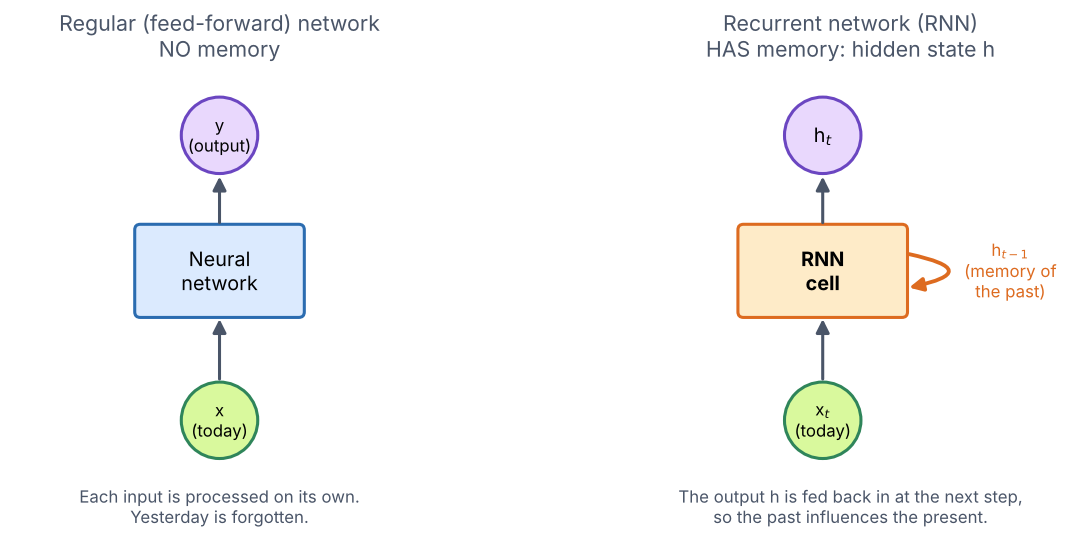

**Everyday analogy.** Reading the sentence *"The river spread over its **bank**"*, you understand "bank" only because you
remember "river" from earlier in the sentence. The hidden state is the RNN's version of that running memory.

## 4.2 The one formula an RNN uses
At every time step `t`, the RNN cell combines **today's input** $x_t$ with **yesterday's memory** $h_{t-1}$:

$$h_t = \tanh\left(w_x \cdot x_t \;+\; w_h \cdot h_{t-1} \;+\; b\right)$$

| Symbol | Meaning | In our stock example |
|---|---|---|
| $x_t$ | input at step `t` | the (scaled) opening price on day `t` |
| $h_{t-1}$ | memory from the previous step ($h_0 = 0$ at the start) | a summary of all earlier days |
| $w_x$ | weight for the input | how much "today" matters |
| $w_h$ | weight for the memory | how much "the past" matters |
| $b$ | bias | a constant offset |
| $\tanh$ | activation function | squashes the result into (−1, 1) so it never blows up |
| $h_t$ | new memory (hidden state) | passed to the next day, and used for the prediction |

**Key idea:** the **same weights** $w_x, w_h, b$ are used at **every** step. The RNN does not learn separate weights for day 1,
day 2, …; it learns **one rule for updating its memory** and applies it repeatedly. Training (backpropagation through time)
is simply the process of finding good values for these weights.

In the real model the numbers become vectors and matrices (50 hidden units, so $h_t$ holds 50 numbers), but the idea is identical.

## 4.3 A tiny worked example, step by step
To keep it small, imagine an RNN with **one** hidden unit that sees **three days** of scaled prices and predicts day 4.

* Inputs (scaled prices, rising): $x_1 = 0.2,\; x_2 = 0.5,\; x_3 = 0.9$
* Weights (pretend they were already learned): $w_x = 1.0,\; w_h = 0.5,\; b = 0$; output layer $\hat{y} = 1.1 \cdot h_3$
* Start with an empty memory: $h_0 = 0$

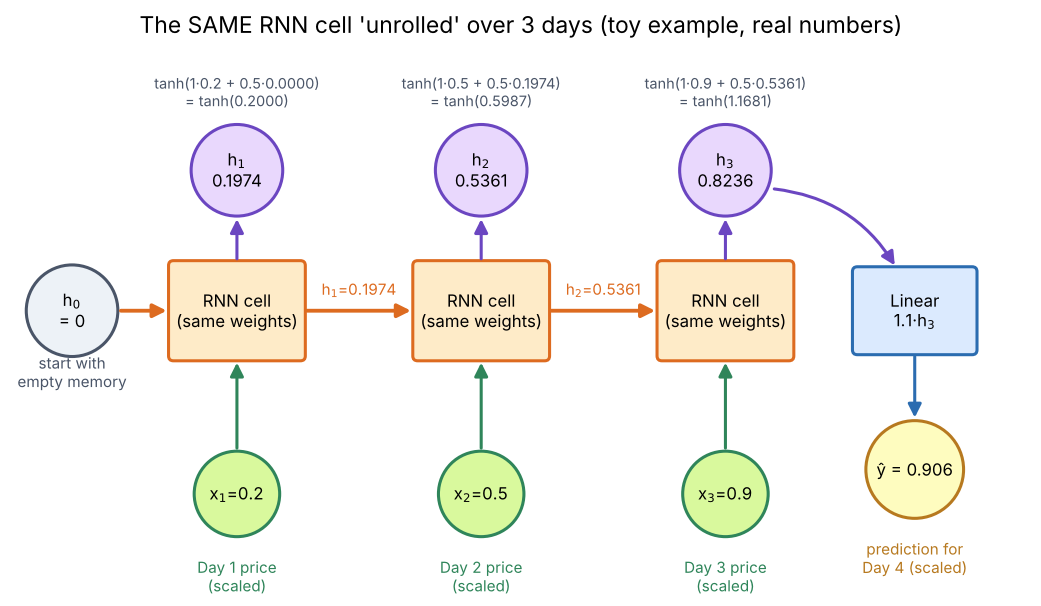

| Step | What happens | Calculation | Result |
|---|---|---|---|
| **Day 1** | Read $x_1$; memory is empty | $h_1 = \tanh(1.0 \cdot 0.2 + 0.5 \cdot 0) = \tanh(0.2000)$ | $h_1 = 0.1974$ |
| **Day 2** | Read $x_2$ **and** remember day 1 | $h_2 = \tanh(1.0 \cdot 0.5 + 0.5 \cdot 0.1974) = \tanh(0.5987)$ | $h_2 = 0.5361$ |
| **Day 3** | Read $x_3$ **and** remember days 1–2 (through $h_2$) | $h_3 = \tanh(1.0 \cdot 0.9 + 0.5 \cdot 0.5361) = \tanh(1.1681)$ | $h_3 = 0.8236$ |
| **Predict** | Turn the final memory into a price | $\hat{y} = 1.1 \cdot 0.8236$ | $\hat{y} = 0.906$ |

Notice that $h_3$ depends on **all three** days: $x_3$ directly, $x_2$ through $h_2$, and $x_1$ through $h_1 \rightarrow h_2$.
This chain is how the RNN "remembers". Drawing the loop as a chain of copies, as above, is called **unrolling** the RNN in time.

Here is what happens inside the cell at Day 2:

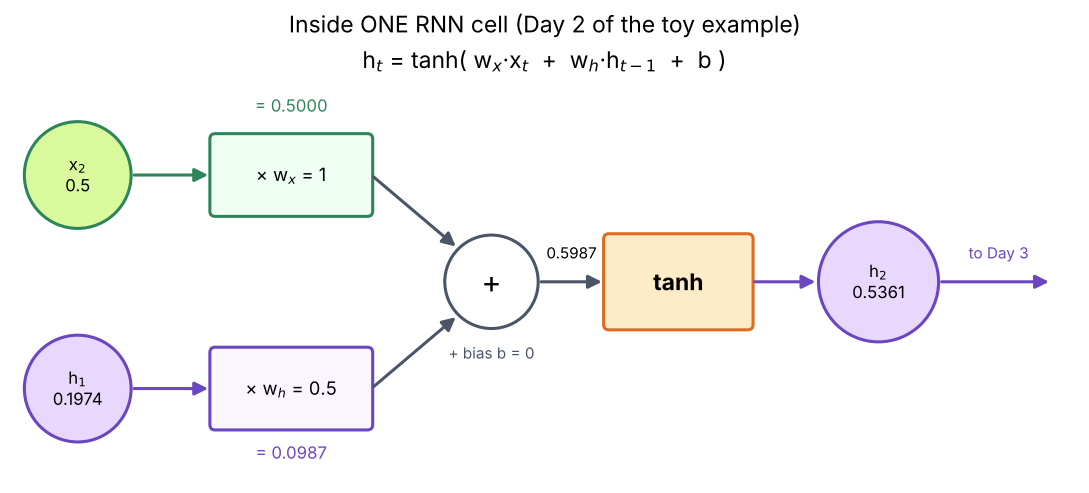

And this is where the three steps land on the $\tanh$ curve — whatever the input, the memory always stays between −1 and 1:

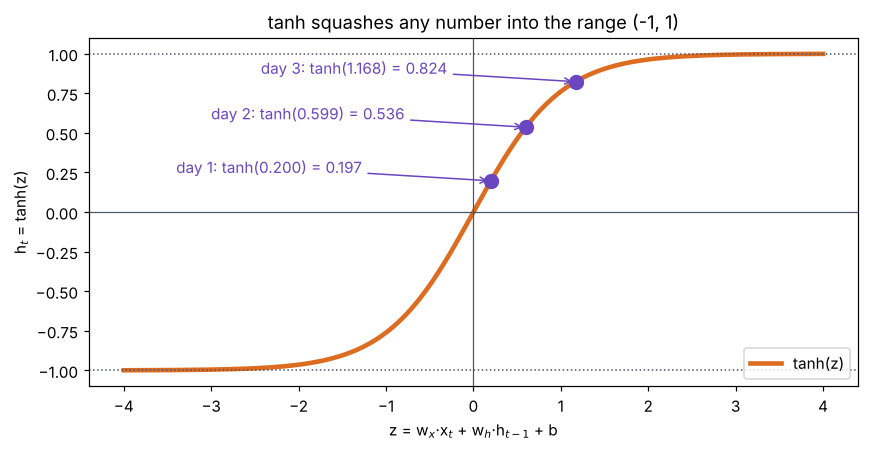

## 4.4 Check the example in code (runs instantly on a CPU)
The cell below repeats the calculation by hand with a `for` loop, then lets PyTorch's own `nn.RNN` do it with the same weights.
It also shows that **order matters**: the same three prices in falling order give a different memory and prediction.

In [ ]:
import math                                   # math.tanh for the hand calculation.
import torch                                  # PyTorch, to compare with the real nn.RNN layer.
from torch import nn                          # nn.RNN lives here.

x_days = [0.2, 0.5, 0.9]                      # Three days of scaled opening prices (a rising trend).
w_x, w_h, b, w_y = 1.0, 0.5, 0.0, 1.1         # The pretend "already learned" weights from the example.


def tiny_rnn(sequence):
    h = 0.0                                   # h0 = 0: start with an empty memory.
    for t, x in enumerate(sequence, start=1): # Read the sequence one day at a time.
        h = math.tanh(w_x * x + w_h * h + b)  # The RNN formula: mix today's input with yesterday's memory.
        print(f"  day {t}: x = {x:.1f} -> h_{t} = {h:.4f}")  # Show the memory after each day.
    return w_y * h                            # Output layer: turn the final memory into a prediction.


print("Rising prices  [0.2, 0.5, 0.9]:")
print(f"  prediction for day 4 = {tiny_rnn(x_days):.4f}")        # Expect 0.9060.
print("Falling prices [0.9, 0.5, 0.2] (same numbers, reversed order):")
print(f"  prediction for day 4 = {tiny_rnn(x_days[::-1]):.4f}")  # Different result: the RNN noticed the order.

# The same calculation with PyTorch's nn.RNN (1 input feature, 1 hidden unit, tanh activation).
rnn = nn.RNN(input_size=1, hidden_size=1, batch_first=True)  # A real RNN layer with random weights...
with torch.no_grad():                         # ...which we overwrite with our example weights.
    rnn.weight_ih_l0.fill_(w_x)               # Input weight w_x.
    rnn.weight_hh_l0.fill_(w_h)               # Recurrent (memory) weight w_h.
    rnn.bias_ih_l0.fill_(b)                   # Input bias (PyTorch uses two biases; together they make b).
    rnn.bias_hh_l0.fill_(0.0)                 # Recurrent bias set to 0.
    seq = torch.tensor(x_days).reshape(1, 3, 1)  # Shape (batch=1, time steps=3, features=1).
    outputs, h_last = rnn(seq)                # outputs = h1, h2, h3; h_last = h3.
print("nn.RNN hidden states:", outputs.flatten().numpy().round(4))  # Same h1, h2, h3 as the hand calculation.

## 4.5 How this connects to the stock model in Problem 1
**1. Data → sequences.** One long price series is cut into many overlapping windows. Each window of 60 days is an input `X`,
and the next day's price is its target `y`.

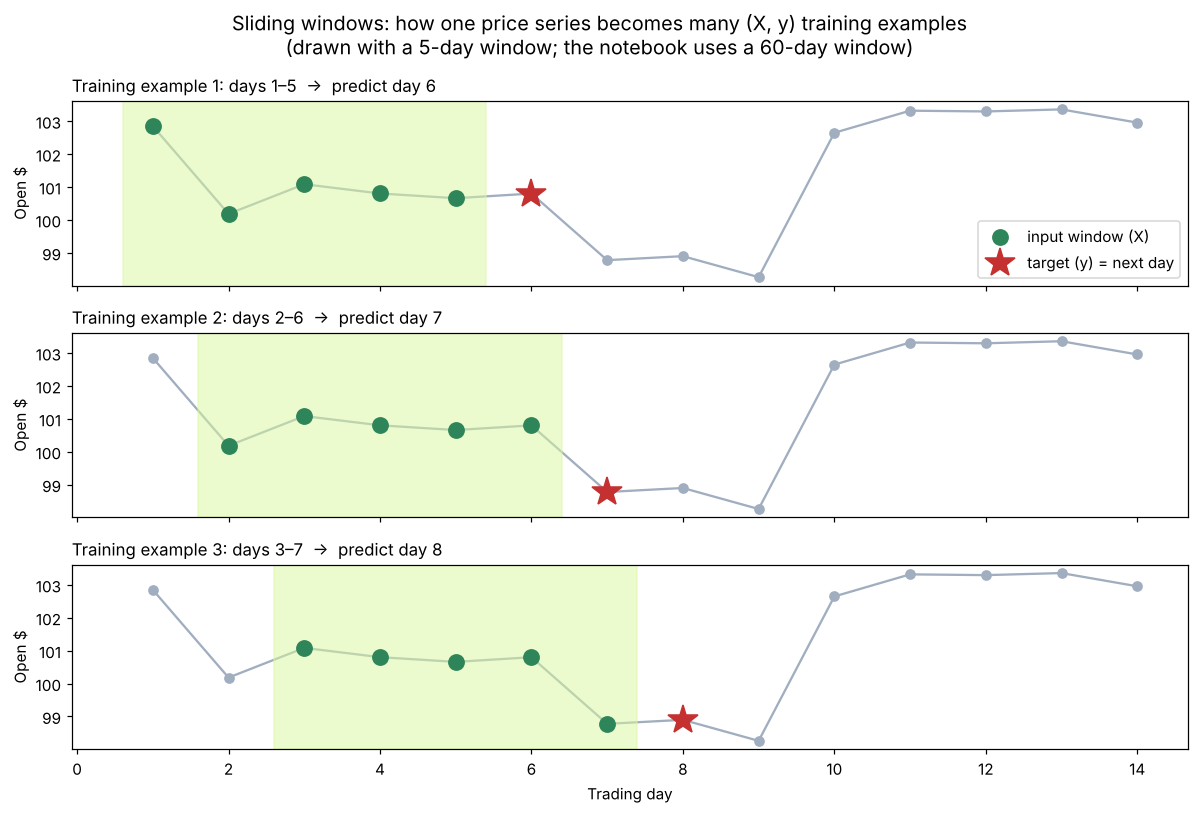

**2. Sequence → prediction (many-to-one).** The network reads the 60 days one by one, exactly like the 3-day toy example.
Our model stacks **4 RNN layers**: layer 1 reads the prices, and each higher layer reads the sequence of memories from the layer below,
so it can detect more abstract patterns. Only the **last** memory of the top layer (50 numbers summarising all 60 days) goes into the
Linear layer, which outputs **one** number: the next day's opening price. This one-output-per-sequence setup is called **many-to-one**.

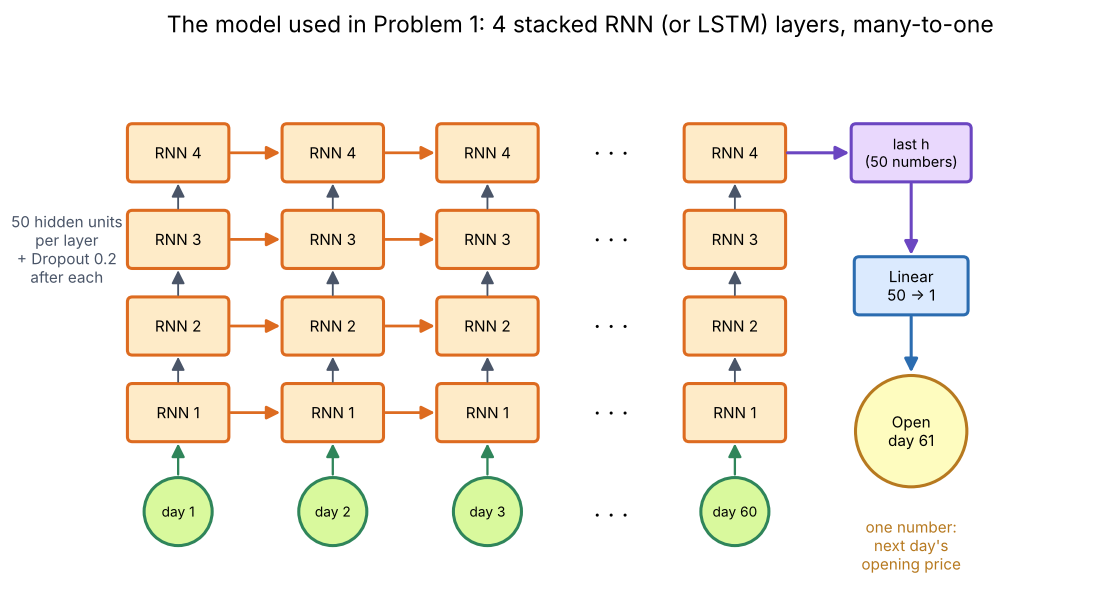

**3. Learning.** At first the weights are random and the predictions are poor. For each batch the error (MSE) is measured and
**backpropagation through time** sends the error backwards through all 60 steps to work out how each weight should change; Adam then
adjusts the weights. After 100 epochs the weights encode a useful "memory update rule" for this stock.

## 4.6 The weakness of a plain RNN, and why the LSTM exists
During backpropagation the learning signal for an early day is multiplied by a factor at **every** step it travels back.
If that factor is below 1, the signal shrinks exponentially — the **vanishing gradient** problem — so a plain RNN effectively
learns only from the most recent few days. (If the factor is above 1, the gradients *explode*; that is why our training code clips them.)

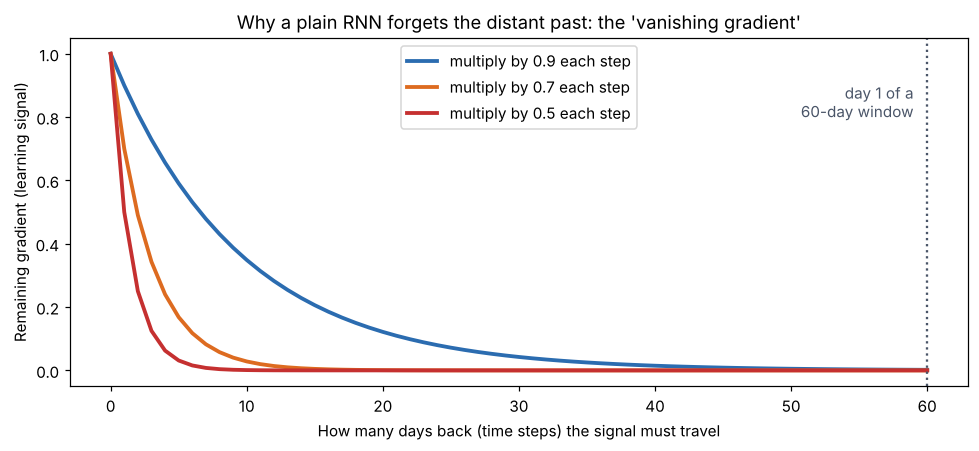

The **LSTM** (Long Short-Term Memory) fixes this by adding a second, protected memory — the **cell state** — and three **gates**,
small learned switches between 0 and 1:

| Gate | Question it answers |
|---|---|
| **Forget gate** | Which parts of the old memory should be erased? |
| **Input gate** | Which parts of today's information should be written into memory? |
| **Output gate** | Which parts of the memory should be shown as the output $h_t$ today? |

Because the cell state is updated mostly by *adding* new information instead of repeatedly multiplying, useful information
(and its gradient) can survive across many time steps. That is why the LSTM in Problem 1 usually trains to a lower loss and gives
smoother predictions than the vanilla RNN.

## 4.7 Summary in five sentences
1. An **RNN** processes a sequence **one step at a time**, keeping a **hidden state** that acts as memory.
2. At every step it applies the **same** rule $h_t = \tanh(w_x x_t + w_h h_{t-1} + b)$ with the **same** weights.
3. The final hidden state summarises the entire sequence and is turned into a prediction by a normal (Linear) layer.
4. The weights are learned with **backpropagation through time**, which treats the unrolled RNN like a deep network.
5. Plain RNNs forget long-ago steps (vanishing gradients); **LSTMs** use gates and a cell state to remember for longer.